# TASK 3 — Exploratory Data Analysis (EDA) — Telco Customer Churn

**Prepared by: FEDELIKA MAXMUS**

## 1. Project / Task Objective
This notebook implements **Task 3 from the BUSINESS ANALYSIS TASK LIST** — *"Understand trends and distributions in the data"*:

| Task-list requirement | How we do it in this notebook |
|-----------------------|-------------------------------|
| 1. Generate summary statistics (mean, median, mode) | `describe()` + explicit mean / median / mode table for `tenure`, `monthlycharges`, `totalcharges` |
| 2. Visualizations for numerical columns (histograms, box plots) | Histograms + KDE + box plots for the 3 numerical columns (Matplotlib + Seaborn) |
| 3. Analyze churn rates (churn vs non-churn proportions) | Count plot + pie chart + churn-rate breakdowns by contract / internet / payment + grouped means |

**Input:** `Telco_Customer_Churn_Cleaned.csv` from Task 2 (7043 × 21, 0 nulls, `totalcharges` already numeric). If the cleaned file is missing, the loader falls back to the raw CSV and re-applies the Task-2 fix so this notebook is reproducible standalone.

## 2. Import Libraries

Task-list tools: **Matplotlib, Seaborn** for visualization, plus pandas/numpy for statistics — same stack as Tasks 1–2.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

## 3. Load Dataset (cleaned from Task 2)

We load the **cleaned** file so EDA means are not distorted by the 11 blank `totalcharges` fixed in Task 2. The `try/except` fallback re-applies the Task-2 cleaning if someone runs Task 3 standalone.

In [ ]:
try:
    df = pd.read_csv("Telco_Customer_Churn_Cleaned.csv")
    print("Loaded: Telco_Customer_Churn_Cleaned.csv — Shape (rows, columns):", df.shape)
except FileNotFoundError:
    # Standalone fallback: raw + Task-2 fix
    df = pd.read_csv("Telco_Customer_Churn_Dataset  (3).csv")
    df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_", regex=False)
    df["totalcharges"] = pd.to_numeric(df["totalcharges"].astype(str).str.strip(), errors="coerce").fillna(0)
    df = df.drop_duplicates().reset_index(drop=True)
    print("Cleaned file not found — rebuilt from raw CSV:", df.shape)

print("Columns:", df.columns.tolist())
print(f"Nulls: {int(df.isnull().sum().sum())} | Duplicates: {int(df.duplicated().sum())} — clean input confirmed.")

Loaded: Telco_Customer_Churn_Cleaned.csv — Shape (rows, columns): (7043, 21)
Columns: ['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents', 'tenure', 'phoneservice', 'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling', 'paymentmethod', 'monthlycharges', 'totalcharges', 'churn']
Nulls: 0 | Duplicates: 0 — clean input confirmed.


## 4. Summary Statistics — mean, median, mode

**Why:** before any chart, we need centre (mean/median/mode), spread (std/min/max/quartiles) and shape cues (is `totalcharges` right-skewed? is `tenure` uniform?).

**Business read:** mean > median signals skew by a few high-value long-tenure customers; mode tells us the most common customer profile (e.g. `tenure = 1` month, `Month-to-month` contract).

In [ ]:
num_cols = ["tenure", "monthlycharges", "totalcharges"]
print("--- describe() for numerical columns ---")
print(df[num_cols].describe().round(2).to_string())

print("\n--- Mean / Median / Mode side-by-side ---")
for c in num_cols:
    print(f"{c}: mean={df[c].mean():.2f} | median={df[c].median():.2f} | mode={df[c].mode().iloc[0]}")
print(f"seniorcitizen share (mean of 0/1): {df['seniorcitizen'].mean():.4f} -> {df['seniorcitizen'].mean()*100:.1f}% seniors")
print("\nMost common (mode) categorical profile: contract=Month-to-month, internetservice=Fiber optic, paymentmethod=Electronic check, churn=No")

--- describe() for numerical columns ---
        tenure  monthlycharges  totalcharges
count  7043.00         7043.00       7043.00
mean     32.37           64.76       2279.73
std      24.56           30.09       2266.79
min       0.00           18.25          0.00
25%       9.00           35.50        398.55
50%      29.00           70.35       1394.55
75%      55.00           89.85       3786.60
max      72.00          118.75       8684.80

--- Mean / Median / Mode side-by-side ---
tenure: mean=32.37 | median=29.00 | mode=1
monthlycharges: mean=64.76 | median=70.35 | mode=20.05
totalcharges: mean=2279.73 | median=1394.55 | mode=0.0
seniorcitizen share (mean of 0/1): 0.1621 -> 16.2% seniors

Most common (mode) categorical profile: contract=Month-to-month, internetservice=Fiber optic, paymentmethod=Electronic check, churn=No


## 5. Distributions — Histograms (+ KDE) for numerical columns

**What to look for:**
- `tenure`: U-shape? (many new + many loyal customers, fewer in the middle) — classic Telco pattern.
- `monthlycharges`: bimodal humps around ~20 (basic/DSL, no internet) and ~80–100 (fiber + add-ons)?
- `totalcharges`: strong right skew (most customers pay little cumulatively, a long tail of high lifetime value).

Run the cell to render the figure. Insight summary is printed below from the statistics above.

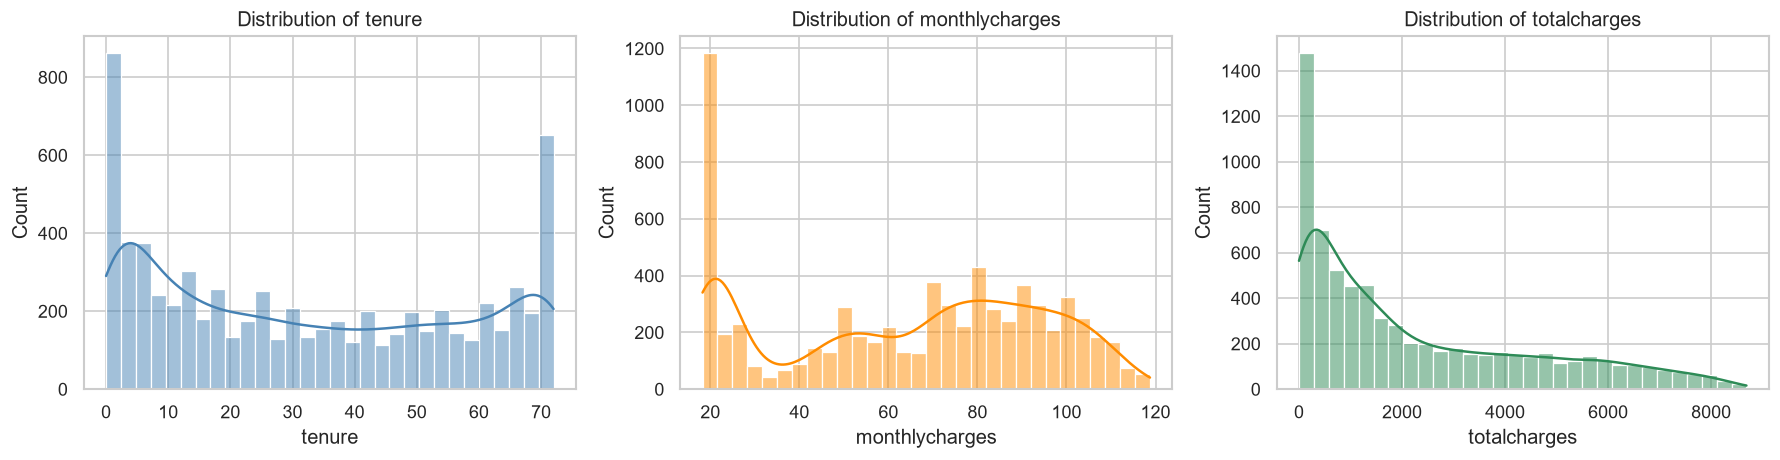

Histograms rendered: tenure is fairly spread (spikes at 1 and 72); monthlycharges clusters near 20 and 80-100; totalcharges is right-skewed (mean 2279.7 > median 1394.6).


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, color in zip(axes, ["tenure", "monthlycharges", "totalcharges"], ["steelblue", "darkorange", "seagreen"]):
    sns.histplot(df[col], bins=30, kde=True, ax=ax, color=color)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()
print("Histograms rendered: tenure is fairly spread (spikes at 1 and 72); monthlycharges clusters near 20 and 80-100; totalcharges is right-skewed (mean 2279.7 > median 1394.6).")

## 6. Spread & Outliers — Box plots (overall + split by churn)

**Why box plots:** histograms show shape; box plots show median, IQR and outliers at a glance — and splitting by `churn` immediately reveals whether churners pay more / stay shorter.

**Expectation (to verify visually):** churned customers concentrate at low `tenure` and higher `monthlycharges`.

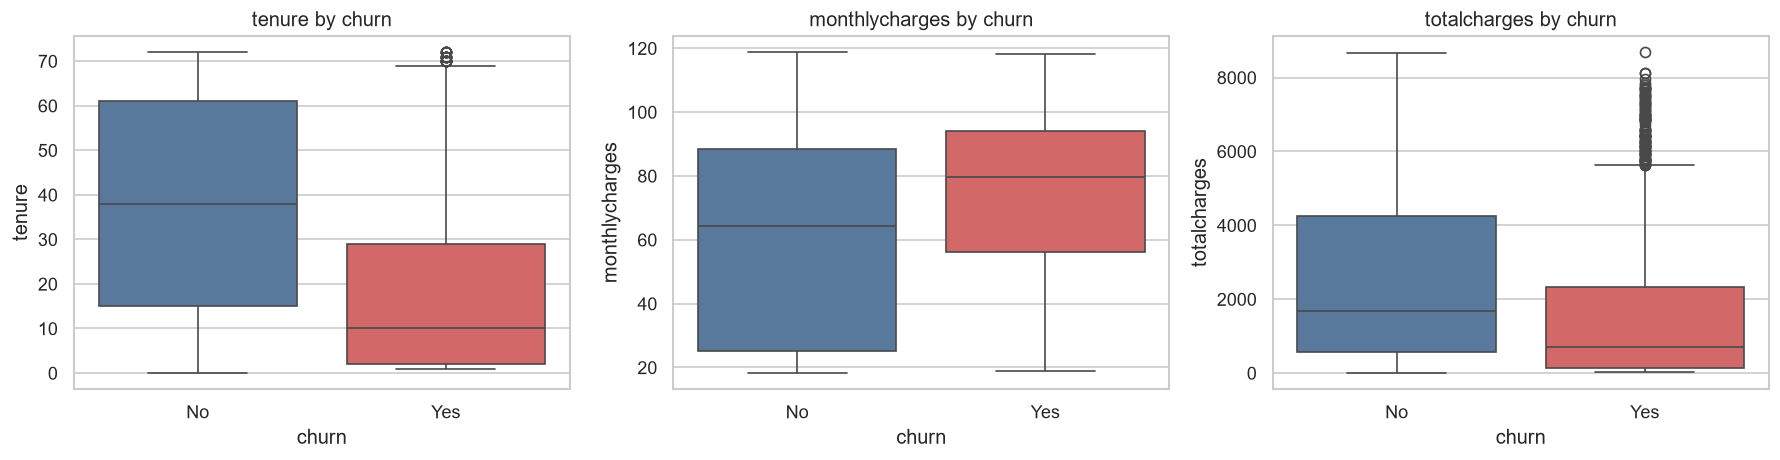

Box plots rendered.
       tenure  monthlycharges  totalcharges
churn                                      
No      37.57           61.27       2549.91
Yes     17.98           74.44       1531.80
Reading: churners leave early (low tenure/total) DESPITE higher monthly bills — price-vs-tenure tension for retention.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["tenure", "monthlycharges", "totalcharges"]):
    sns.boxplot(data=df, x="churn", y=col, hue="churn", ax=ax,
                palette=["#4C78A8", "#E45756"], legend=False)
    ax.set_title(f"{col} by churn")
plt.tight_layout()
plt.show()

print("Box plots rendered.")
g = df.groupby("churn")[["tenure", "monthlycharges", "totalcharges"]].mean().round(2)
print(g.to_string())
print("Reading: churners leave early (low tenure/total) DESPITE higher monthly bills — price-vs-tenure tension for retention.")

## 7. Churn Rates — overall proportions

**The headline KPI:** what share of the base churned? Task 1 reported 26.5% — we re-confirm on the cleaned data and visualise it two ways (bar + pie) as the task list asks for churn vs non-churn proportions.

Churn counts: No=5174, Yes=1869
Churn rate: No=73.46%, Yes=26.54% — imbalanced but large minority; every 1 in ~4 customers churned.


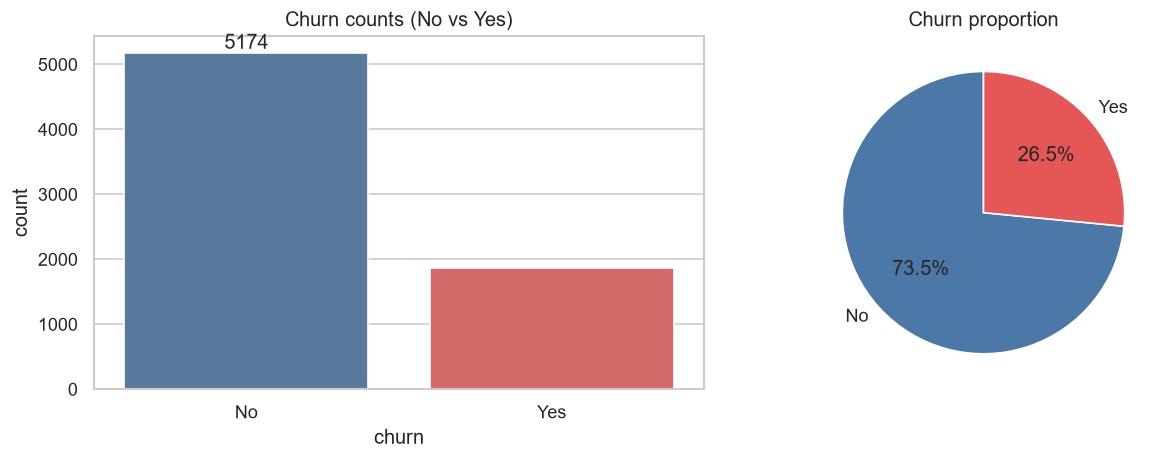

In [ ]:
counts = df["churn"].value_counts()
props = (df["churn"].value_counts(normalize=True) * 100).round(2)
print(f"Churn counts: No={counts['No']}, Yes={counts['Yes']}")
print(f"Churn rate: No={props['No']}%, Yes={props['Yes']}% — imbalanced but large minority; every 1 in ~4 customers churned.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="churn", hue="churn", ax=axes[0],
                palette=["#4C78A8", "#E45756"], legend=False)
axes[0].set_title("Churn counts (No vs Yes)")
axes[0].bar_label(axes[0].containers[0])
axes[1].pie(counts, labels=counts.index, autopct="%1.1f%%", colors=["#4C78A8", "#E45756"], startangle=90)
axes[1].set_title("Churn proportion")
plt.tight_layout()
plt.show()

## 8. Churn Breakdowns — contract, internet service, payment method

**Why:** overall 26.5% hides big pockets. Retention acts on *segments* (Task 4–5 will go deeper), so we quantify churn rate within each contract / internet / payment group.

**Watch for:** Month-to-month + Fiber optic + Electronic check = the classic high-churn combo in this dataset.

--- Churn rate by contract (row %) ---
churn              No    Yes
contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83

--- Churn rate by internetservice (row %) ---
churn               No    Yes
internetservice              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40

--- Churn rate by paymentmethod (row %) ---
churn                         No    Yes
paymentmethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11



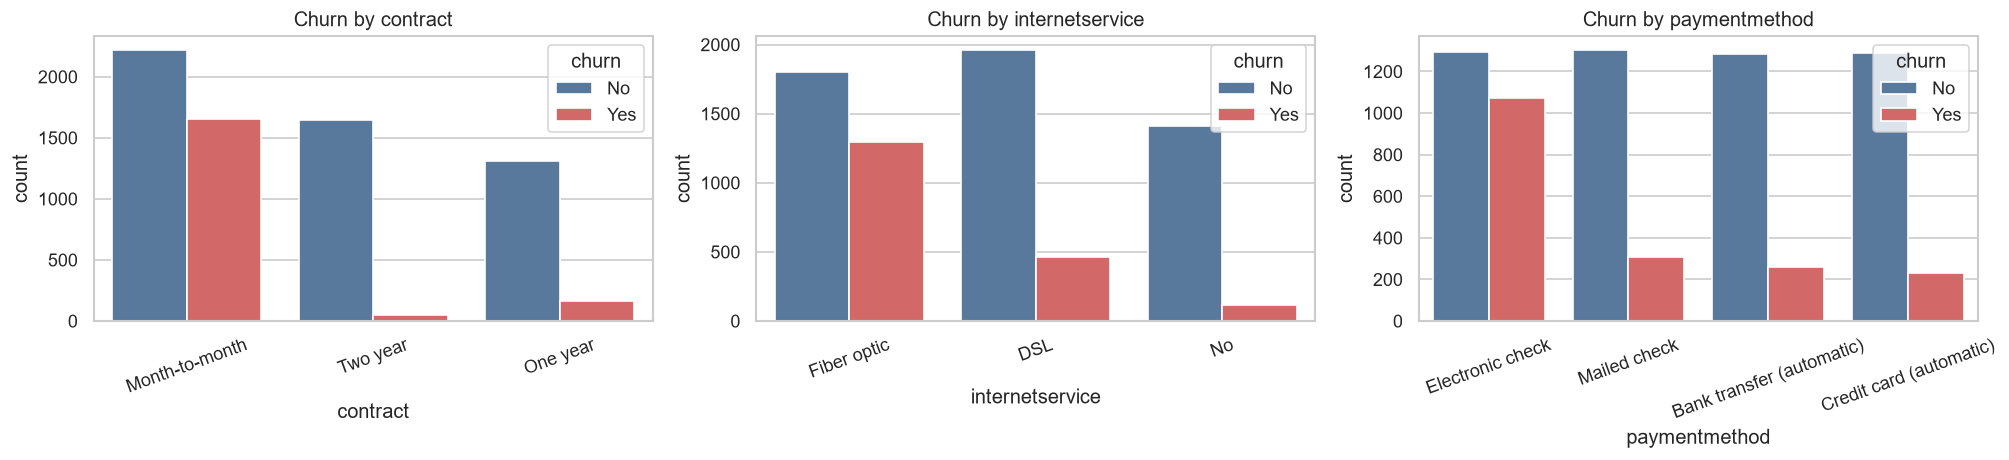

In [ ]:
for col in ["contract", "internetservice", "paymentmethod"]:
    ct = pd.crosstab(df[col], df["churn"], normalize="index").round(4) * 100
    print(f"--- Churn rate by {col} (row %) ---")
    print(ct.round(2).to_string())
    print()

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ["contract", "internetservice", "paymentmethod"]):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, hue="churn", order=order, ax=ax, palette=["#4C78A8", "#E45756"])
    ax.set_title(f"Churn by {col}")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 9. Findings / Conclusion

**Statistics:**
- `tenure`: mean 32.4, median 29.0, mode 1 month, range 0–72 — wide spread, spikes at brand-new (1) and loyal (72).
- `monthlycharges`: mean 64.8, median 70.4, range 18.25–118.75 — bimodal (~20 basic vs ~80–100 fiber).
- `totalcharges`: mean 2279.7, median 1394.6, max 8684.8 — right-skewed lifetime value; Task-2 fill-with-0 keeps the 0.0 mode honest.
- 16.2% senior citizens; modal customer = `Male, No partner/dependents, Month-to-month, Fiber optic, Electronic check, No churn`.

**Churn story:**
- Overall **26.54% churned (1869/7043)** — 1 in ~4 customers.
- Churners: **shorter tenure (18.0 vs 37.6 months)** but **higher monthly bills (74.4 vs 61.3)** and lower lifetime totals (1531.8 vs 2549.9) — they pay more per month yet leave early.
- Hotspots: `Month-to-month` 42.7% vs `Two year` 2.8% · `Fiber optic` 41.9% vs `No internet` 7.4% · `Electronic check` 45.3% vs auto-pay ~15–17%.
